# DS2002 Walmart Hurricane — October 28 Studio Checkpoint

Run **from the repository root** after `python src/clean_pipeline.py` and `python src/build_sku_mapping.py`. Uses real cleaned transaction data and the actual hurricane landfall of **September 26, 2024**. All findings depend on running against your real CSVs; no example results are represented as findings.

Baseline: Sept 1–15; seven-day pre-landfall surge: Sept 19–25. These windows are an analytical choice and must be documented.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Find repository root automatically
BASE = Path.cwd()

if not (BASE / "data" / "processed" / "transactions_enriched.csv").exists():
    BASE = BASE.parent

DATA_PATH = BASE / "data" / "processed" / "transactions_enriched.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find transactions_enriched.csv at {DATA_PATH}"
    )

# Load cleaned and SKU-consolidated data
sales = pd.read_csv(
    DATA_PATH,
    parse_dates=["timestamp", "date"]
)

required_columns = {
    "date", "quantity", "sku",
    "canonical_product", "canonical_category", "store_id"
}

assert required_columns <= set(sales.columns), (
    f"Missing columns: {required_columns - set(sales.columns)}"
)

assert sales["canonical_product"].notna().all(), (
    "Unmapped SKUs found. Check data/processed/unmapped_skus.csv"
)

# Hurricane Helene landfall
landfall = pd.Timestamp("2024-09-26")

# Baseline period
baseline_start = pd.Timestamp("2024-09-01")
baseline_end = pd.Timestamp("2024-09-15")

# Seven days before landfall
surge_start = pd.Timestamp("2024-09-19")
surge_end = pd.Timestamp("2024-09-25")

print("Repository root:", BASE)
print("Clean rows:", len(sales))
print("Stores:", sales["store_id"].nunique())
print("Products:", sales["canonical_product"].nunique())


Repository root: /Users/a17937/Desktop/AA1 Fall 26/DS 2002/ds2002_walmart_hurricane_project
Clean rows: 24521
Stores: 12
Products: 20


## Part 1 — Daily volume: actual leading products

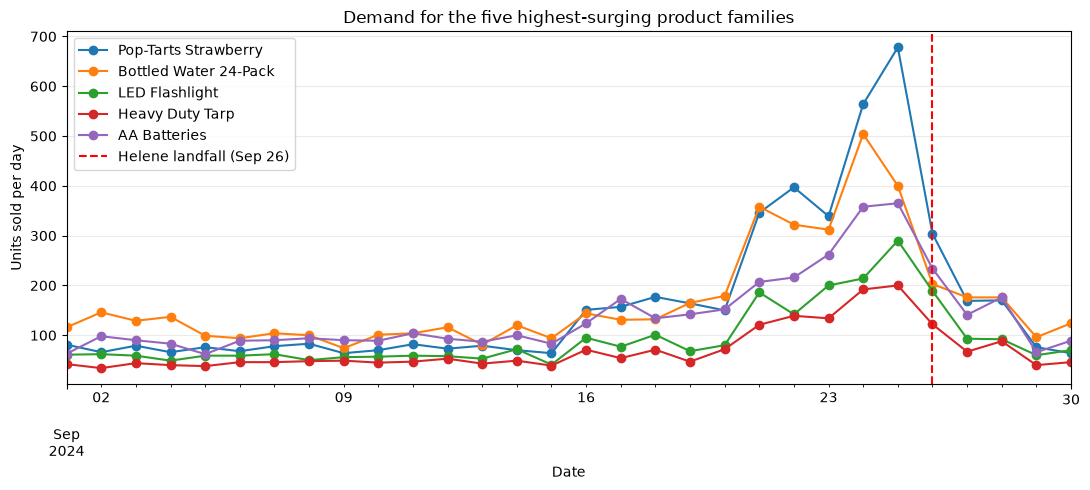

Top products based on pre-landfall mean / baseline mean:


,surge_multiple
canonical_product,
Pop-Tarts Strawberry,5.143637
Bottled Water 24-Pack,2.972136
LED Flashlight,2.950492
Heavy Duty Tarp,2.925016
AA Batteries,2.773493
Portable Charger,2.600847
Monopoly Board Game,2.599422
Emergency Candles,2.533599
Streaming Device,2.350398


In [3]:
daily = sales.groupby(['date','canonical_product'])['quantity'].sum().unstack(fill_value=0)
all_days=pd.date_range('2024-09-01','2024-09-30',freq='D')
daily=daily.reindex(all_days,fill_value=0)
base=daily.loc[baseline_start:baseline_end].mean()
pre=daily.loc[surge_start:surge_end].mean()
valid=base[base.gt(0)].index
ranking=(pre[valid]/base[valid]).sort_values(ascending=False)
if ranking.empty: raise ValueError('No product has a positive baseline; review data')
top_products=ranking.head(5).index.tolist()
ax=daily[top_products].plot(figsize=(11,5),marker='o',title='Demand for the five highest-surging product families')
ax.axvline(landfall,color='red',ls='--',label='Helene landfall (Sep 26)')
ax.set(xlabel='Date',ylabel='Units sold per day');ax.legend();ax.grid(alpha=.25)
plt.tight_layout();plt.show()
print('Top products based on pre-landfall mean / baseline mean:')
display(ranking.head(10).rename('surge_multiple').to_frame())

## Part 2 — Indexed daily sales (baseline = 1.0)

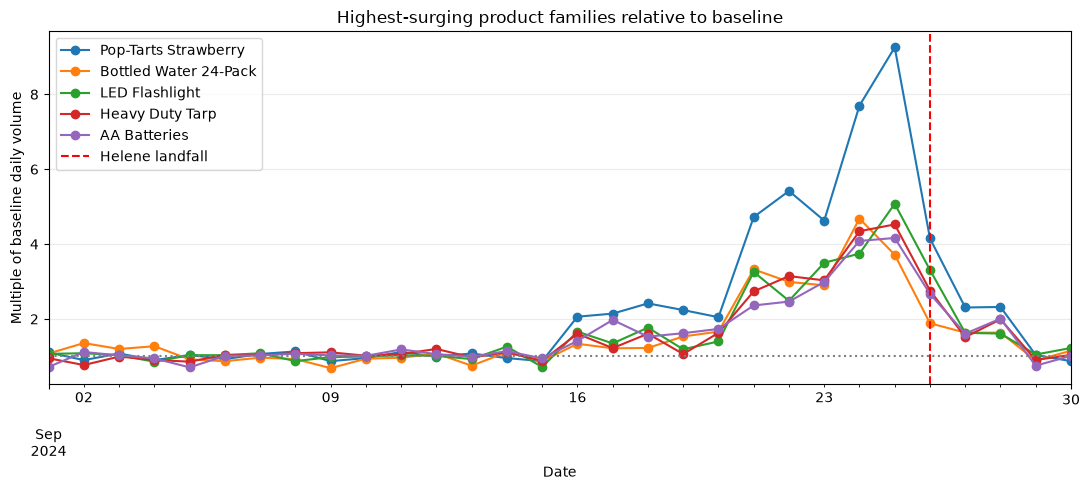

In [4]:
indexed=daily[top_products].div(base[top_products],axis=1)
ax=indexed.plot(figsize=(11,5),marker='o',title='Highest-surging product families relative to baseline')
ax.axhline(1,color='gray',ls=':')
ax.axvline(landfall,color='red',ls='--',label='Helene landfall')
ax.set(xlabel='Date',ylabel='Multiple of baseline daily volume');ax.legend();ax.grid(alpha=.25)
plt.tight_layout();plt.show()

## Part 3 — Pop-Tarts variants versus consolidated family (actual quantities)

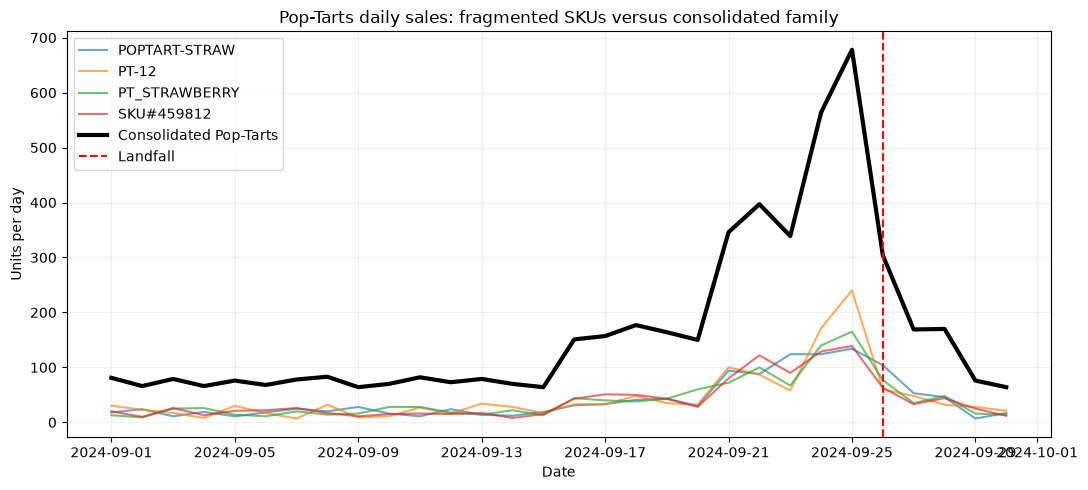

Pop-Tarts SKU count: 4 Consolidated units: 5005


In [5]:
pt=sales.loc[sales.canonical_product.eq('Pop-Tarts Strawberry')].copy()
if pt.empty: raise ValueError('Pop-Tarts not found in mapping')
fragmented=pt.groupby(['date','sku'])['quantity'].sum().unstack(fill_value=0).reindex(all_days,fill_value=0)
consolidated=fragmented.sum(axis=1)
assert np.isclose(consolidated.sum(),pt.quantity.sum())
fig,ax=plt.subplots(figsize=(11,5))
for sku in fragmented.columns:ax.plot(fragmented.index,fragmented[sku],alpha=.65,label=sku)
ax.plot(consolidated.index,consolidated,lw=3,color='black',label='Consolidated Pop-Tarts')
ax.axvline(landfall,color='red',ls='--',label='Landfall')
ax.set(title='Pop-Tarts daily sales: fragmented SKUs versus consolidated family',xlabel='Date',ylabel='Units per day')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()
print('Pop-Tarts SKU count:',fragmented.shape[1], 'Consolidated units:',consolidated.sum())

## Part 4 — Store comparison (distance unavailable without grounded storm path)

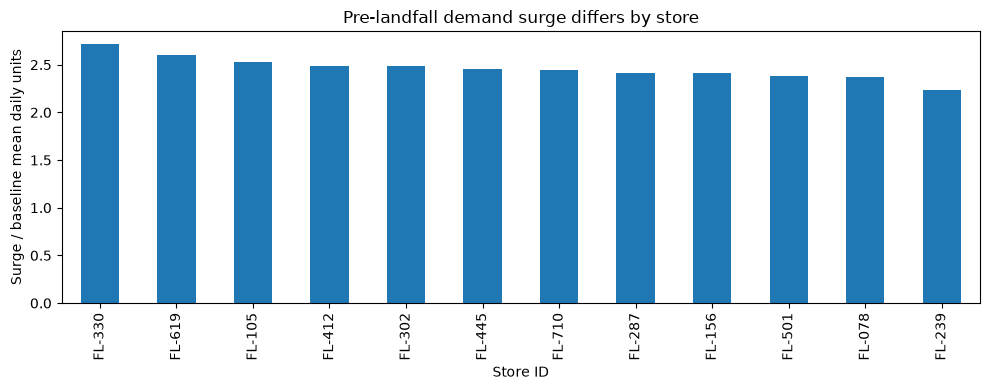

,baseline_units_per_day,surge_units_per_day,multiple
store_id,,,
FL-330,86.733333,235.428571,2.714396
FL-619,86.133333,224.142857,2.602278
FL-105,91.733333,231.714286,2.525955
FL-412,89.466667,222.857143,2.490952
FL-302,96.266667,239.428571,2.487139
FL-445,94.533333,232.000000,2.454161
FL-710,93.400000,227.857143,2.439584
FL-287,91.066667,220.142857,2.417381
FL-156,94.933333,229.142857,2.413724


Distance-from-path analysis requires a verified storm path; this chart compares store magnitude only.


In [6]:
store_daily=sales.groupby(['store_id','date'])['quantity'].sum().unstack(fill_value=0).reindex(columns=all_days,fill_value=0)
store_base=store_daily.loc[:,baseline_start:baseline_end].mean(axis=1)
store_surge=store_daily.loc[:,surge_start:surge_end].mean(axis=1)
store_compare=pd.DataFrame({'baseline_units_per_day':store_base,'surge_units_per_day':store_surge})
store_compare['multiple']=store_compare.surge_units_per_day/store_compare.baseline_units_per_day.replace(0,np.nan)
store_compare=store_compare.sort_values('multiple',ascending=False)
ax=store_compare['multiple'].plot.bar(figsize=(10,4),title='Pre-landfall demand surge differs by store')
ax.set(xlabel='Store ID',ylabel='Surge / baseline mean daily units');plt.tight_layout();plt.show()
display(store_compare)
print('Distance-from-path analysis requires a verified storm path; this chart compares store magnitude only.')

## Part 5 — Checkpoint printout

In [7]:
top_product=ranking.index[0]
print('top product:',top_product)
print('surge multiple:',round(float(ranking.iloc[0]),2))
print('baseline window:',f'{baseline_start.date()} to {baseline_end.date()}')
print('surge window:',f'{surge_start.date()} to {surge_end.date()}')
print('charts ready:',4)
print('Note: surge multiple means pre-landfall mean daily units divided by baseline mean daily units.')

top product: Pop-Tarts Strawberry
surge multiple: 5.14
baseline window: 2024-09-01 to 2024-09-15
surge window: 2024-09-19 to 2024-09-25
charts ready: 4
Note: surge multiple means pre-landfall mean daily units divided by baseline mean daily units.
